# 09 · 奖励怎么改变回答概率？
上一课：模型查到库存，参数没有改变。本课：根据回答得分，真正更新参数。

本节使用 **3 个可训练数值的教学策略**，不是 Transformer，也不会因此学会通用加法。它只回答一道固定题「2 + 2 等于多少」，从 3、4、5 三个答案里选一个。这样能把每个概率、梯度和参数都看清。

只用本机 CPU，无网络、无模型下载。选择项目的 Python 内核。按顺序逐格运行；重复第 1 格会重置参数。**今天可以只看第 1、2 格，后面逐步学。**

## 1 · 三个参数怎样变成三个概率？
输入：三个分数 logits。输出：和为 1 的三个概率。参数不是概率，softmax 才把它们变成概率。这里用 log 构造初值，让概率恰好为 0.3、0.4、0.3。

In [1]:
import torch
torch.set_printoptions(precision=4, sci_mode=False)
answers = ["3", "4", "5"]
initial = torch.tensor([0.3, 0.4, 0.3]).log()
logits = torch.nn.Parameter(initial.clone())  # 这是本课全部可训练参数
optimizer = torch.optim.SGD([logits], lr=0.5)
before = logits.softmax(dim=0).detach().clone()
print("参数 logits：", logits.detach())
for answer, probability in zip(answers, before):
    print("答案", answer, "概率", round(probability.item(), 4))

参数 logits： tensor([-1.2040, -0.9163, -1.2040])
答案 3 概率 0.3
答案 4 概率 0.4
答案 5 概率 0.3


## 2 · 评分程序只告诉它得几分
输入一个回答字符串，输出 0 或 1。评分器知道标准答案，但不会把正确答案当作目标 token 塞进下面的 RL loss。

In [3]:
def reward(answer):
    return float(answer == "4")

for answer in answers:
    print(answer, "→", reward(answer))
print("初始平均奖励 =", sum(before[i].item() * reward(a) for i, a in enumerate(answers)))


3 → 0.0
4 → 1.0
5 → 0.0
初始平均奖励 = 0.4000000059604645


## 3 · 模型自己尝试，再计算优势
从当前概率分布采样 16 次，不能先挑好正确答案。固定随机种子便于复现；这不是改写采样结果。

优势 A = 奖励 R − 基准 b。先固定 b=0.4，即本题初始策略的平均奖励。之后仍可固定用它，只是它不再代表更新后模型的平均分。基准不依赖这次选到哪个答案。

In [ ]:
torch.manual_seed(7)
distribution = torch.distributions.Categorical(logits=logits)
actions = distribution.sample((16,))  # 形状 [16]；每个值是答案下标
rewards = torch.tensor([reward(answers[i]) for i in actions.tolist()])
baseline = 0.4
advantages = rewards - baseline
for i, r, a in zip(actions.tolist(), rewards.tolist(), advantages.tolist()):
    print(f"回答 {answers[i]}   奖励 {r:.0f}   优势 {a:+.1f}")
print("这批实际平均奖励：", rewards.mean().item())
print("此时参数没更新：", torch.equal(before, logits.softmax(0).detach()))

回答 3   奖励 0   优势 -0.4
回答 3   奖励 0   优势 -0.4
回答 5   奖励 0   优势 -0.4
回答 4   奖励 1   优势 +0.6
回答 5   奖励 0   优势 -0.4
回答 5   奖励 0   优势 -0.4
回答 3   奖励 0   优势 -0.4
回答 4   奖励 1   优势 +0.6
回答 5   奖励 0   优势 -0.4
回答 5   奖励 0   优势 -0.4
回答 3   奖励 0   优势 -0.4
回答 3   奖励 0   优势 -0.4
回答 3   奖励 0   优势 -0.4
回答 3   奖励 0   优势 -0.4
回答 3   奖励 0   优势 -0.4
回答 5   奖励 0   优势 -0.4
这批实际平均奖励： 0.125
此时参数没更新： True


## 4 · 奖励不是可求导函数，怎么训练？
先看一项：$L=-A\log p$。再对 16 次尝试取平均。正优势鼓励这次采样到的答案；负优势抑制它。

**求导的是 log 概率。** 采样的下标、奖励、优势都当作固定值。我们不对字符串比较求导。

这叫带基准的 REINFORCE，是基础策略梯度。目标是提高期望奖励；这个 loss 是用来产生梯度的代理量，不是分类错误率，也没有一个训练到位的固定数值。

In [4]:
log_probs = distribution.log_prob(actions)
terms = -advantages * log_probs
loss = terms.mean()
print("前四次 log 概率：", log_probs[:4].detach())
print("前四项 loss：", terms[:4].detach())
print("平均 loss：", loss.item())
print("奖励需要梯度吗：", rewards.requires_grad)
print("loss 需要梯度吗：", loss.requires_grad)

前四次 log 概率： tensor([-1.2040, -1.2040, -1.2040, -0.9163])
前四项 loss： tensor([-0.4816, -0.4816, -0.4816,  0.5498])
平均 loss： -0.3526687026023865
奖励需要梯度吗： False
loss 需要梯度吗： True


## 5 · backward 只计算梯度，step 才更新参数
先猜：正确答案对应的参数会变大还是变小？
SGD 更新：新参数 = 旧参数 − 学习率 × 梯度。所以负梯度会让参数增加。softmax 把三个概率绑在一起，一个改变，其余也会改变。

In [5]:
optimizer.zero_grad()
loss.backward()
old_logits = logits.detach().clone()
gradient = logits.grad.detach().clone()
print("旧参数：", old_logits)
print("梯度：  ", gradient)
print("按公式算的新参数：", old_logits - 0.5 * gradient)
optimizer.step()
after = logits.softmax(0).detach().clone()
print("实际新参数：", logits.detach())
for i, answer in enumerate(answers):
    print(f"答案 {answer}：{before[i]:.4f} → {after[i]:.4f}")
assert torch.allclose(logits.detach(), old_logits - 0.5 * gradient)
assert after[1] > before[1]  # 固定这批数据的结果；不是任意复杂模型的保证

旧参数： tensor([-1.2040, -0.9163, -1.2040])
梯度：   tensor([ 0.1175, -0.1850,  0.0675])
按公式算的新参数： tensor([-1.2627, -0.8238, -1.2377])
实际新参数： tensor([-1.2627, -0.8238, -1.2377])
答案 3：0.3000 → 0.2796
答案 4：0.4000 → 0.4337
答案 5：0.3000 → 0.2867


## 6 · 同一模型，用 SFT 会怎么写？
SFT 直接提供正确答案的下标 1，loss = −log P(4)。RL 的 loss 则来自自己采样的答案和它们的优势。下面从相同初值比较一次梯度，不改变上面已训练的参数。

In [6]:
sft_logits = initial.clone().requires_grad_()
sft_loss = -sft_logits.log_softmax(0)[1]
sft_loss.backward()
print("SFT：标准答案下标 = 1")
print("SFT 梯度：", sft_logits.grad)
print("RL 这批采样的梯度：", gradient)
print("本例可能方向相同、力度不同；RL 的梯度还受采样结果影响。")

SFT：标准答案下标 = 1
SFT 梯度： tensor([ 0.3000, -0.6000,  0.3000])
RL 这批采样的梯度： tensor([ 0.1175, -0.1850,  0.0675])
本例可能方向相同、力度不同；RL 的梯度还受采样结果影响。


## 7 · 反复尝试、评分、更新
每次更新后重新采样，不拿旧采样反复当作新数据。接下来从初值重新训练 60 步，避免重复运行本格时接着上次的参数继续。

本题只有 3 种答案，可以精确计算平均奖励 P(4)。真实大模型通常不能枚举全部回答，只能通过采样估计。

In [7]:
torch.manual_seed(17)
policy = torch.nn.Parameter(initial.clone())
opt = torch.optim.SGD([policy], lr=0.3)
history = [policy.softmax(0).detach().tolist()]
batch_scores = []
for step in range(60):
    dist = torch.distributions.Categorical(logits=policy)
    choices = dist.sample((32,))
    scores = torch.tensor([reward(answers[i]) for i in choices.tolist()])
    advantage = scores - 0.4
    objective = -(advantage * dist.log_prob(choices)).mean()
    opt.zero_grad()
    objective.backward()
    opt.step()
    batch_scores.append(scores.mean().item())
    history.append(policy.softmax(0).detach().tolist())

print(f"精确平均奖励：{history[0][1]:.4f} → {history[-1][1]:.4f}")
print("只说明这道固定题更常选 4，不能说明会算新题。")
assert history[-1][1] > history[0][1]

精确平均奖励：0.4000 → 0.9536
只说明这道固定题更常选 4，不能说明会算新题。


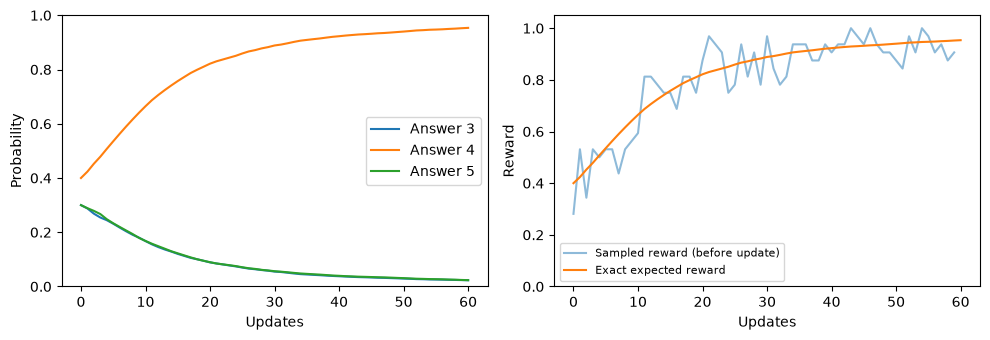

In [8]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for i, answer in enumerate(answers):
    axes[0].plot([row[i] for row in history], label=f"Answer {answer}")
axes[0].set(xlabel="Updates", ylabel="Probability", ylim=(0, 1))
axes[0].legend()
axes[1].plot(range(60), batch_scores, alpha=0.5, label="Sampled reward (before update)")
axes[1].plot(range(61), [row[1] for row in history], label="Exact expected reward")
axes[1].set(xlabel="Updates", ylabel="Reward", ylim=(0, 1.05))
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 8 · 为什么不能只看奖励？
如果评分器错误地给所有回答同样的分数，模型就没有能区分正确与错误的奖励信号。下面把基准设成同一个分数，优势全为 0，梯度也为 0。

如果所有得分相同而基准不同，单批采样仍可能产生随机梯度，但它在期望上不偏好正确答案。不是“只要给分，就会学会”。

In [9]:
probe = initial.clone().requires_grad_()
dist = torch.distributions.Categorical(logits=probe)
choices = dist.sample((16,))
same_rewards = torch.ones(16)
zero_advantage = same_rewards - 1.0
no_signal_loss = -(zero_advantage * dist.log_prob(choices)).mean()
no_signal_loss.backward()
print("梯度：", probe.grad)
assert torch.equal(probe.grad, torch.zeros(3))

梯度： tensor([0., 0., 0.])


## 9 · 对应回真正的大模型
| 本课 | 大模型 RL 中对应什么 |
|---|---|
| 三个 logits | 由模型权重计算出的各 token 的 logits |
| 一次选一个答案 | 逐 token 采样出一段回答 |
| 回答得 0 或 1 | 规则或奖励模型给出的分数 |
| 一个 log 概率 | 回答各 token 条件 log 概率之和 |
| 更新三个数 | 更新模型权重，或 LoRA 参数 |

一句回答的概率是各 token 条件概率的乘积，取 log 后变成求和。因此最终奖励可以用来调整这段回答的生成概率，但“哪一步该负责”会比本课复杂。

本课没有实现 PPO 或 GRPO，没有参考模型、KL 约束、裁剪或价值网络。先理解基础更新，之后再学这些训练稳定性问题。不能从这道题的奖励曲线断言大模型能力提高了。

**停下来解释这三个问题：**
1. 第 3 格结束后，模型是否已学到什么？依据是什么？
2. 为什么答错的奖励是 0，仍然可能产生梯度？
3. 评分程序把“答案很长”当作好答案，会把模型往哪个方向训练？

数学来源：[策略梯度与基准的推导](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html)。本课是单状态、单动作步的教学特例。